# Batch monitoring tool

### 0. Import modules

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

import os
from pathlib import Path

### 1. Data loading

In [2]:
current_dir = os.path.abspath(os.getcwd())
root_dir = os.path.dirname(current_dir)
data_dir = os.path.join(root_dir, 'data','raw', 'solar')

In [3]:
df_plant1 = pd.read_csv(os.path.join(data_dir, "Plant_1_Generation_Data.csv"))
df_plant1['DATE_TIME'] = pd.to_datetime(df_plant1['DATE_TIME'])
print(df_plant1.info())
print(df_plant1.describe())    

df_plant2 = pd.read_csv(os.path.join(data_dir, "Plant_2_Generation_Data.csv"))
df_plant2['DATE_TIME'] = pd.to_datetime(df_plant2['DATE_TIME'])
print(df_plant2.info())
print(df_plant2.describe()) 


/var/folders/c0/kz76jmcs33d7z3cs14xpr_pc0000gn/T/ipykernel_8089/1272292827.py:2: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_plant1['DATE_TIME'] = pd.to_datetime(df_plant1['DATE_TIME'])


<class 'pandas.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   DATE_TIME    68778 non-null  datetime64[us]
 1   PLANT_ID     68778 non-null  int64         
 2   SOURCE_KEY   68778 non-null  str           
 3   DC_POWER     68778 non-null  float64       
 4   AC_POWER     68778 non-null  float64       
 5   DAILY_YIELD  68778 non-null  float64       
 6   TOTAL_YIELD  68778 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 4.7 MB
None
                        DATE_TIME   PLANT_ID      DC_POWER      AC_POWER  \
count                       68778    68778.0  68778.000000  68778.000000   
mean   2020-06-01 08:02:49.458257  4135001.0   3147.426211    307.802752   
min           2020-05-15 00:00:00  4135001.0      0.000000      0.000000   
25%           2020-05-24 00:45:00  4135001.0      0.000000      0.000000   


### 2. Functions

In [4]:
def parse_timestamps(time_values: pd.Series) -> pd.Series:
    """Parse DATE_TIME with an explicit format (not to let pandas guess day vs month)."""
    for fmt in ["%d-%m-%Y %H:%M", "%Y-%m-%d %H:%M:%S"]:
        parsed = pd.to_datetime(time_values, format=fmt, errors="coerce")
        if parsed.notna().all():
            return parsed
    raise ValueError(f"Unknown date format")


def load_generation(path) -> pd.DataFrame:
    """One row per inverter and timestamp: timestamp, inverter, ac_power (kW)."""
    df = pd.read_csv(path)
    return pd.DataFrame({
        "timestamp": parse_timestamps(df["DATE_TIME"]),
        "inverter": df["SOURCE_KEY"].astype(str),
        "ac_power": df["AC_POWER"].astype(float),
    })


def load_weather(path) -> pd.DataFrame:
    """One row per timestamp: irradiation (kW/m2), module_temperature (degC)."""
    df = pd.read_csv(path)
    return pd.DataFrame({
        "timestamp": parse_timestamps(df["DATE_TIME"]),
        "irradiation": df["IRRADIATION"].astype(float),
        "module_temperature": df["MODULE_TEMPERATURE"].astype(float),
    })


def load_plant(raw_dir, plant: int) -> pd.DataFrame:
    """Generation and weather of one plant, merged on timestamp."""
    raw_dir = Path(raw_dir)
    generation = load_generation(raw_dir / f"Plant_{plant}_Generation_Data.csv")
    weather = load_weather(raw_dir / f"Plant_{plant}_Weather_Sensor_Data.csv")
    weather = weather.drop_duplicates("timestamp")
    return generation.merge(weather, on="timestamp", how="left")


# ----------------------------------------------------------------- cleaning
def remove_duplicates(df) -> tuple[pd.DataFrame, int]:
    before = len(df)
    df = df.drop_duplicates(["inverter", "timestamp"])
    return df, before - len(df)


def remove_impossible_values(df) -> tuple[pd.DataFrame, int]:
    """Negative power or irradiation is a sensor error -> NaN."""
    df = df.copy()
    bad = (df["ac_power"] < 0) | (df["irradiation"] < 0)
    df.loc[bad, ["ac_power", "irradiation"]] = float("nan")
    return df, int(bad.sum())


def remove_frozen_power(df, n_repeats = 4) -> tuple[pd.DataFrame, int]:
    """A non-zero power value repeated n_repeats times in a row => frozen sensor -> NaN."""
    df = df.sort_values(["inverter", "timestamp"]).copy()
    same_as_previous = df.groupby("inverter")["ac_power"].diff().eq(0)
    run_length = same_as_previous.groupby((~same_as_previous).cumsum()).cumsum()
    frozen = (run_length >= n_repeats - 1) & (df["ac_power"] > 0)
    df.loc[frozen, "ac_power"] = float("nan")
    return df, int(frozen.sum())


def clean(df) -> tuple[pd.DataFrame, dict]:
    """Basic data-quality pass. Returns (clean table, report of what was found)."""
    df, n_duplicates = remove_duplicates(df)
    df, n_impossible = remove_impossible_values(df)
    df, n_frozen = remove_frozen_power(df)
    report = {"duplicates": n_duplicates, "impossible_values": n_impossible, "frozen_points": n_frozen}
    return df, report


In [5]:

# ----------------------------------------------------------- inverter runs
def add_date_and_time(df: pd.DataFrame) -> pd.DataFrame:
    """date = '2020-05-15', time = decimal hours (06:15 -> 6.25)."""
    df = df.copy()
    df["date"] = df["timestamp"].dt.date.astype(str)
    df["time"] = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60
    return df


def keep_daylight(df: pd.DataFrame) -> pd.DataFrame:
    return df[df["time"].between(START_HOUR, END_HOUR)]


def complete_grid(df: pd.DataFrame) -> pd.DataFrame:
    """Every inverter run gets every time point; missing measurements become NaN."""
    days = df[["inverter", "date"]].drop_duplicates()
    times = pd.DataFrame({"time": np.arange(START_HOUR, END_HOUR + STEP_HOURS, STEP_HOURS)})
    grid = days.merge(times, how="cross")
    return grid.merge(df[["inverter", "date", "time", *PARAMS]], on=["inverter", "date", "time"], how="left")


def name_batches(df: pd.DataFrame) -> pd.DataFrame:
    """One name per inverter run: batch_1, batch_2, ... (sorted by inverter, then date)."""
    days = df[["inverter", "date"]].drop_duplicates().sort_values(["inverter", "date"])
    days["batch_id"] = [f"batch_{i}" for i in range(1, len(days) + 1)]
    return df.merge(days, on=["inverter", "date"])


def drop_dark_days(df: pd.DataFrame, min_daily_irradiation: float = 1.0) -> pd.DataFrame:
    """Runs with almost no sun: their normalised quality is meaningless."""
    daily_sun = df.groupby("batch_id")["irradiation"].transform("sum")
    return df[daily_sun >= min_daily_irradiation]


def daily_quality(values: pd.DataFrame) -> pd.Series:
    """Per batch: sum of AC power / sum of irradiation."""
    totals = values.groupby("batch_id")[["ac_power", "irradiation"]].sum()
    return totals["ac_power"] / totals["irradiation"]



def fill_short_gaps(values: pd.DataFrame, max_gap: int = 2) -> pd.DataFrame:
    """Linear interpolation inside each batch, only for holes of at most max_gap points."""
    values = values.sort_values(["batch_id", "time"]).copy()
    for param in PARAMS:
        missing = values[param].isna()
        hole_id = (~missing).cumsum()                                    # consecutive NaNs share an id
        hole_length = missing.groupby([values["batch_id"], hole_id]).transform("sum")
        interpolated = values.groupby("batch_id")[param].transform(
            lambda s: s.interpolate(limit_area="inside")                 # never extrapolate at the edges
        )
        short_hole = missing & (hole_length <= max_gap)
        values.loc[short_hole, param] = interpolated[short_hole]
    return values


def drop_incomplete_batches(values: pd.DataFrame, quality: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Remove every batch that still has at least one NaN."""
    row_has_nan = values[PARAMS].isna().any(axis=1)
    batch_has_nan = row_has_nan.groupby(values["batch_id"]).any()
    complete = batch_has_nan.index[~batch_has_nan]
    print(f"dropped {batch_has_nan.sum()} incomplete batches out of {len(batch_has_nan)}")
    return values[values["batch_id"].isin(complete)], quality[quality["batch_id"].isin(complete)]




In [37]:

# ------------------------------------------------------------------ pipeline
def prepare_plant(raw_dir, plant) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load -> clean -> inverter runs -> fill short gaps. Returns (values, quality)."""
    df = load_plant(raw_dir, plant)
    df, report = clean(df)
    print(f"plant {plant}, cleaning:", report)

    df = add_date_and_time(df)
    df = keep_daylight(df)
    df = complete_grid(df)
    df = name_batches(df)
    df = drop_dark_days(df)
    values = df[["batch_id", "time", "date", *PARAMS]].sort_values(["batch_id", "time"]).reset_index(drop=True)

    batches = df[["batch_id", "inverter", "date"]].drop_duplicates().reset_index(drop=True)
    values = fill_short_gaps(values, max_gap=2)
    values, batches = drop_incomplete_batches(values, batches)

    quality = batches.copy()
    quality.insert(1, "quality", quality["batch_id"].map(daily_quality(values)))
    return values, quality



### 2. Data Preprocessing

In [38]:
START_HOUR, END_HOUR, STEP_HOURS = 6.0, 18.5, 0.25   # daylight window, 15-min grid
PARAMS = ["ac_power", "irradiation", "module_temperature"]

In [39]:
original_cleaned = load_plant(data_dir, 1)
print("number of inverters: ", original_cleaned['inverter'].nunique() ,", each running for ", int(original_cleaned['timestamp'].nunique() / (23 * 4)), "days") 

number of inverters:  22 , each running for  34 days


In [47]:
values, quality = prepare_plant(data_dir, plant=1)

plant 1, cleaning: {'duplicates': 0, 'impossible_values': 0, 'frozen_points': 0}
dropped 155 incomplete batches out of 748


In [43]:
values

,batch_id,time,date,ac_power,irradiation,module_temperature
0,batch_1,6.00,2020-05-15,3.585714,0.005887,22.206757
1,batch_1,6.25,2020-05-15,26.862500,0.022282,22.353459
2,batch_1,6.50,2020-05-15,60.685714,0.049410,22.893282
3,batch_1,6.75,2020-05-15,119.275000,0.095394,24.442444
4,batch_1,7.00,2020-05-15,170.014286,0.141940,27.185653
...,...,...,...,...,...,...
38143,batch_99,17.50,2020-06-14,98.185714,0.071278,27.996037
38144,batch_99,17.75,2020-06-14,54.962500,0.042898,26.634041
38145,batch_99,18.00,2020-06-14,37.385714,0.029767,25.303088
38146,batch_99,18.25,2020-06-14,24.050000,0.019034,24.723273


In [41]:
values.groupby(['batch_id','date']).count()
print("Number of measurements from 6:00 to 18:30 : ", values['time'].nunique(), "(every 15 mins)")

Number of measurements from 6:00 to 18:30 :  51 (every 15 mins)


### 3. Quality monitoring: inject known faults, compare with peers

Solar has no quality measured independently of the curves, so the truth is created 
(`inject_faults` in `src/earlycall/data/solar.py`):
- 30% of the inverter runs get a fault: **failed string** (power × 0.93 from a random hour between 08:00 and 14:00)
  or **stuck tracker** (from 13:00, power falls gradually to 60% at 18:30)
- label = **faulty yes/no**, known by construction

The weather is removed with **relative power** = inverter power / median of all inverters at the same time
(`add_relative_power`). 1.0 = like its peers.

In [ ]:
from earlycall.data.solar import inject_faults

TRACKER_START = 13.0        # default of inject_faults, used in the plots

values, quality = inject_faults(values, quality.drop(columns="quality"))
quality["faulty"] = quality["quality"].eq(0)          
# 1 = healthy, 0 = faulty
quality = quality.drop(columns="quality")


,batch_id,inverter,date,fault_type,onset,faulty
0,batch_1,1BY6WEcLGh8j5v7,2020-05-15,none,NaN,False
1,batch_2,1BY6WEcLGh8j5v7,2020-05-16,failed string,8.512034,True
2,batch_3,1BY6WEcLGh8j5v7,2020-05-17,failed string,10.693892,True
3,batch_4,1BY6WEcLGh8j5v7,2020-05-18,stuck tracker,13.000000,True
7,batch_8,1BY6WEcLGh8j5v7,2020-05-22,none,NaN,False
...,...,...,...,...,...,...
743,batch_744,zVJPv84UY57bAof,2020-06-13,stuck tracker,13.000000,True
744,batch_745,zVJPv84UY57bAof,2020-06-14,none,NaN,False
745,batch_746,zVJPv84UY57bAof,2020-06-15,none,NaN,False
746,batch_747,zVJPv84UY57bAof,2020-06-16,none,NaN,False


In [50]:
def add_relative_power(values: pd.DataFrame, batches: pd.DataFrame, min_peer_power: float = 50.0) -> pd.DataFrame:
    """relative_power = power / median power of all inverters at the same date and time.

    At dawn and dusk (median below min_peer_power kW) the ratio is unstable: set to 1.0.
    """
    values = values.merge(batches[["batch_id", "date"]], on=["batch_id","date"])
    peer_median = values.groupby(["date", "time"])["ac_power"].transform("median")
    values["relative_power"] = (values["ac_power"] / peer_median).where(peer_median >= min_peer_power, 1.0)
    return values.drop(columns="date")


values = add_relative_power(values, quality)
values = values.merge(quality[["batch_id", "date"]], on="batch_id")
INPUTS = ["relative_power"]

quality["fault_type"].value_counts()

fault_type
none             434
stuck tracker     81
failed string     78
Name: count, dtype: int64

2020-05-16


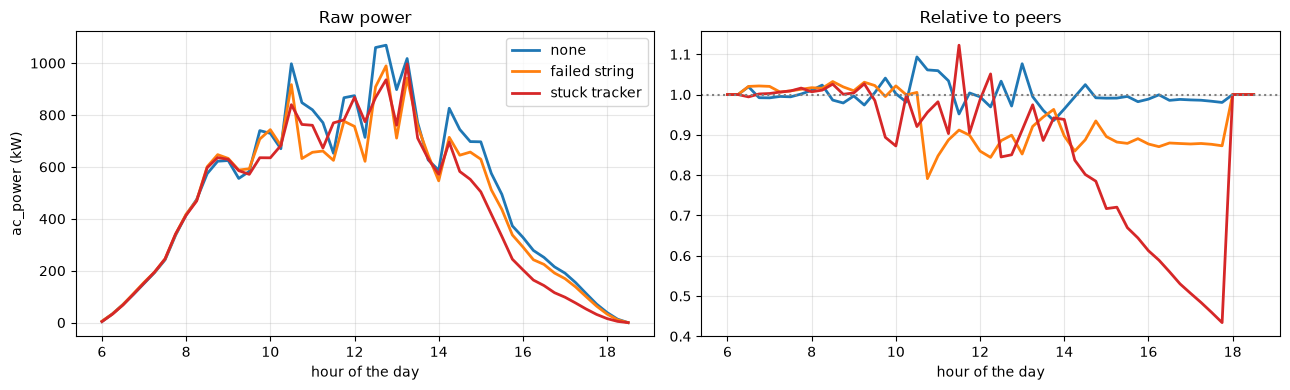

In [70]:
# What the faults look like: one run of each kind
choose_day = quality.loc[quality["fault_type"] == "failed string", "date"].iloc[0]
print(choose_day)

run = values[values["date"] == choose_day]

types = run["batch_id"].map(quality.set_index("batch_id")["fault_type"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for fault, color in [("none", "tab:blue"), ("failed string", "tab:orange"), ("stuck tracker", "tab:red")]:
    if (types == fault).any():
        one = run[run["batch_id"] == run.loc[types == fault, "batch_id"].iloc[0]]
        #plot raw power
        ax1.plot(one["time"], one["ac_power"], color=color, linewidth=2, label=fault)
        #plot relative power
        ax2.plot(one["time"], one["relative_power"], color=color, linewidth=2, label=fault)

ax1.set(title=f"Raw power", ylabel="ac_power (kW)", xlabel="hour of the day")
ax2.set(title="Relative to peers", xlabel="hour of the day")
ax2.axhline(1, color="grey", linestyle=":")
for ax in [ax1,ax2]:
    ax.grid(alpha=0.3)
ax1.legend()
fig.tight_layout()
plt.show()

### 4. Train / test split by date

In [52]:
TEST_SHARE = 0.3

# Sort unique dates chronologically
dates = sorted(quality["date"].unique())

# Reserve the latest 30% of dates for testing
split_idx = int(len(dates) * (1 - TEST_SHARE))
test_dates = dates[split_idx:]

# Split batches by date (never split a day across sets)
is_test = quality["date"].isin(test_dates)

train_ids= quality.loc[~is_test, "batch_id"]
test_ids = quality.loc[is_test, "batch_id"]

# Extract target labels
faulty_train = quality.loc[~is_test, "faulty"]
faulty_test = quality.loc[is_test, "faulty"]

# Report split sizes and fault rates
print(f"Train: {len(train_ids)} batches, {faulty_train.mean():.1%} faulty")
print(f"Test:  {len(test_ids)} batches, {faulty_test.mean():.1%} faulty")
print("Train ends:", quality.loc[~is_test, "date"].max())
print("Test starts:", quality.loc[is_test, "date"].min())

Train: 395 batches, 27.1% faulty
Test:  198 batches, 26.3% faulty
Train ends: 2020-06-08
Test starts: 2020-06-09


### 5. Models

Every `risk_...(seen)` returns one risk per test run: the probability that the run is faulty.
Logistic regression and multiway PLS (from `src/earlycall`) are **trained at each cut time** on the training runs cut at that same time: nothing is invented.

| Model | How it judges a partial run |
|---|---|
| Base rate | same risk for everyone (share of faulty training runs) |
| Last hour vs peers | naive baseline: how far below its peers the inverter was in the last hour |
| Logistic regression | summary features (last, mean, min, max, recent change) of the run seen so far → probability of a fault |
| Multiway PLS | the unfolded run seen so far → 2 PLS components → logistic regression → probability of a fault |
| K-means | nearest cluster of complete runs, using only the hours seen so far; risk = share faulty in the cluster |
| BatchGrouper | nearest group of correlated complete runs (from `src/earlycall`); risk = share faulty in the group |

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

from earlycall.batch_data import BatchData
from earlycall.methods import BatchGrouper, LogisticOnFeatures, MultiwayPLS


# ------------------------------------------------------------------ shared helpers
def seen_until(cut_time):
    return values[values["time"] <= cut_time]


def unfold(curves):
    """One row per batch, one column per (input, time point)."""
    return curves.pivot(index="batch_id", columns="time", values=INPUTS)


train_full = unfold(values).loc[train_ids]        # complete training runs: what every model learns from
average_day = train_full.mean()                    # training average run, one value per (input, time)


In [ ]:

def fill_future(seen):
    """Test runs as known so far; time points not seen yet = the training average run."""
    partial = unfold(seen).loc[test_ids]
    return partial.reindex(columns=train_full.columns).fillna(average_day)


# ------------------------------------------------------------------ fit
#KMeans
scaler = StandardScaler().fit(train_full)
kmeans = KMeans(n_clusters=6, n_init=10, random_state=0).fit(scaler.transform(train_full))
share_faulty_cluster = pd.Series(faulty_train.to_numpy()).groupby(kmeans.labels_).mean()

#Correlation 
batches = quality.assign(quality=np.where(quality["faulty"], 0.0, 1.0))[["batch_id", "quality", "date"]]
all_data = BatchData.from_tables(values[["batch_id", "time", *INPUTS]], batches)
position = {batch: i for i, batch in enumerate(all_data.batch_ids)}
train_data = all_data.subset([position[b] for b in train_ids])
test_data = all_data.subset([position[b] for b in test_ids])
grouper = BatchGrouper(corr_threshold=0.6, min_group_size=3, smoothing_window=4, low_threshold=0.5)
grouper.fit(train_data)

#Logistic regression and multiway PLS: one model per cut time (built when first needed)
logistic = LogisticOnFeatures(low_threshold=0.5).fit(train_data)
pls = MultiwayPLS(n_components=2, low_threshold=0.5).fit(train_data)




In [ ]:


# ------------------------------------------------------------------ risk at a cut time
def risk_base_rate(seen):
    return np.full(len(test_ids), faulty_train.mean())


def risk_last_hour(seen):
    last_hour = seen[seen["time"] > seen["time"].max() - 1]
    level = last_hour.groupby("batch_id")["relative_power"].mean()
    return -level.loc[test_ids].to_numpy()                       # lower than peers = riskier


def risk_logistic(seen):
    return logistic.predict_risk(test_data.X, t_index=seen["time"].nunique())


def risk_pls(seen):
    return pls.predict_risk(test_data.X, t_index=seen["time"].nunique())

"""
def risk_kmeans(seen):
    seen_columns = train_full.columns.get_level_values("time") <= seen["time"].max()
    test_scaled = scaler.transform(fill_future(seen))[:, seen_columns]
    centres = kmeans.cluster_centers_[:, seen_columns]
    distances = ((test_scaled[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
    return share_faulty_cluster.reindex(distances.argmin(axis=1)).to_numpy()
"""

def risk_batchgrouper(seen):
    return grouper.predict_risk(test_data.X, t_index=seen["time"].nunique())


METHODS = {
    "base rate": risk_base_rate,
    #"last hour vs peers": risk_last_hour,
    "logistic": risk_logistic,
    "multiway PLS": risk_pls,
    #"K-means": risk_kmeans,
    "BatchGrouper": risk_batchgrouper,
}
print(f"BatchGrouper: {grouper.n_groups_} groups, {np.mean(grouper.labels_ >= 0):.0%} of training runs grouped")

### 6. Results

**Table 1**: AUC on test runs by hour of the day (1 = faulty runs always ranked riskier, 0.5 = coin flip).
**Table 2**: AUC per fault type (each fault type against the healthy runs) at 16:00 and at the end of the run.

In [ ]:
CUT_TIMES = [8.0, 10.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.5]
info = quality.set_index("batch_id")
fault_type_test = info.loc[test_ids, "fault_type"].to_numpy()

rows = []
for cut_time in CUT_TIMES:
    seen = seen_until(cut_time)
    for method, risk_of in METHODS.items():
        risk = risk_of(seen)
        row = {"method": method, "cut_time": cut_time, "auc": roc_auc_score(faulty_test, risk)}
        for fault in ["failed string", "stuck tracker"]:
            keep = (fault_type_test == fault) | (fault_type_test == "none")
            row[fault] = roc_auc_score(fault_type_test[keep] == fault, risk[keep])
        rows.append(row)
results = pd.DataFrame(rows)

table_1 = results.pivot(index="method", columns="cut_time", values="auc").round(2)
table_2 = results[results["cut_time"].isin([16.0, 18.5])].pivot(
    index="method", columns="cut_time", values=["failed string", "stuck tracker"]).round(2)
display(table_1)
display(table_2)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Plot 1: BatchGrouper's groups, darker = more faulty runs
ax = axes[0]
for g in np.argsort(grouper.group_risk_):
    ax.plot(train_data.time, grouper.reference_[g, 0], linewidth=1.5,
            color=plt.cm.Reds(0.15 + 0.85 * grouper.group_risk_[g]))
ax.axhline(1, color="grey", linestyle=":")
ax.set(xlabel="hour of the day", ylabel="relative power (smoothed)",
       title=f"BatchGrouper: {grouper.n_groups_} groups of training runs (darker = more faulty runs)")
ax.grid(alpha=0.3)

# Plot 2: how early each method detects the faults
#colors = {"last hour vs peers": "grey", "ridge": "tab:blue", "multiway PLS": "tab:green",
         # "K-means": "tab:purple", "BatchGrouper": "tab:red"}

colors = { "logistic": "tab:blue", "multiway PLS": "tab:green", "BatchGrouper": "tab:red"}         
ax = axes[1]
for method, color in colors.items():
    rows_m = results[results["method"] == method]
    ax.plot(rows_m["cut_time"], rows_m["auc"], "--" if method == "last hour vs peers" else "-",
            marker="o", linewidth=3 if method == "BatchGrouper" else 2, color=color, label=method)
ax.axhline(0.5, color="grey", linestyle=":", linewidth=1.5, label="coin flip")
#ax.axvspan(8, 14, color="tab:orange", alpha=0.08, label="failed strings start")
#ax.axvline(TRACKER_START, color="tab:red", linestyle=":", linewidth=1, label="trackers get stuck")
ax.set(ylim=(0.3, 1.02), xlabel="hour of the day reached", ylabel="AUC on test runs",
       title="How early is a faulty inverter detected?")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper left")



fig.tight_layout()
plt.show()